# WP12 — Küçük yerel LLM tasarımı ve uygulanabilirlik
Bu notebook yalnız kabul edilmiş PDF alıntılarını, donanım ölçümünü ve sözleşme testlerini inceler. **LLM çağrısı, model indirme, kurulum ve eğitim içermez.** Tablolardaki NOT_RUN başarı sıfırı değildir; deney yapılmadığını gösterir.

In [1]:
from pathlib import Path
import json, sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = Path.cwd()
if not (ROOT/'AGENTS.md').exists(): ROOT = ROOT.parent
QA = ROOT/'reports/qa/WP12/llm_design_v1'
FIG = ROOT/'reports/figures/WP12/llm_design_v1'
sys.path.insert(0, str(ROOT/'scripts'))
import wp12_llm_contract as contract
hw=json.loads((QA/'hardware_snapshot.json').read_text(encoding='utf-8'))
display(pd.DataFrame([{'Ölçüm':k,'Değer':v} for k,v in {'CPU':hw['cpu'],'Çekirdek/izlek':f"{hw['physical_cores']}/{hw['logical_cores']}",'RAM GiB':hw['ram']['total']/2**30,'Boş RAM GiB':hw['ram']['available']/2**30,'GPU':hw['gpu']['name'],'VRAM MiB':hw['gpu']['total_MiB'],'Ölçüm zamanı':hw['captured_at']}.items()]))

,Ölçüm,Değer
0,CPU,AMD Ryzen 5 4600H with Radeon Graphics (regist...
1,Çekirdek/izlek,6/12
2,RAM GiB,7.421165
3,Boş RAM GiB,0.774601
4,GPU,NVIDIA GeForce GTX 1650 Ti
5,VRAM MiB,4096
6,Ölçüm zamanı,2026-11-08T03:07:15.686921+03:00


## Donanımda ne öğrendik?
RAM ve VRAM farklı kaynaklardır; boş GPU belleği host RAM eksikliğini ortadan kaldırmaz. Aşağıdaki anlık ölçüm cihazın kalıcı boşluk garantisi değildir. Dosya boyutu, çıkarım tepe belleği değildir.

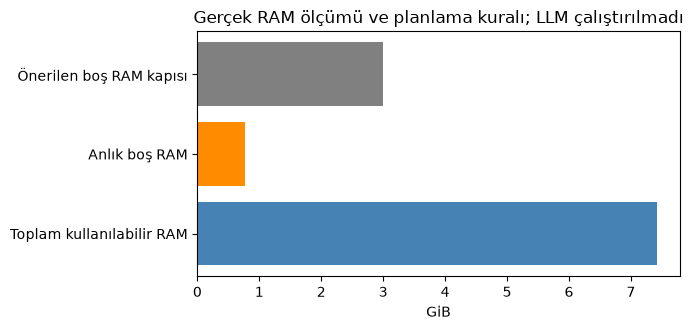

In [2]:
fig,ax=plt.subplots(figsize=(7,3.4))
total=hw['ram']['total']/2**30; available=hw['ram']['available']/2**30
ax.barh(['Toplam kullanılabilir RAM','Anlık boş RAM','Önerilen boş RAM kapısı'],[total,available,3],color=['steelblue','darkorange','grey'])
ax.set_xlabel('GiB'); ax.set_title('Gerçek RAM ölçümü ve planlama kuralı; LLM çalıştırılmadı')
fig.tight_layout();fig.savefig(FIG/'01_memory_snapshot.png',dpi=150,bbox_inches='tight');plt.show()

**Yorum:** Anlık boş RAM önerilen 3GiB planlama eşiğinden düşüktür. Bu eşik üretici gereksinimi veya sığma garantisi değildir. Bu tasarım mevcut durumda çalıştırma önermez. Bellek serbest bırakılması kullanıcı işlemi olacaktır.

,tag,registry_size_GB,local_cache_manifest,position,limitation
0,qwen3:1.7b,1.400,False,Birincil küçük model adayı; gelecekte ayrıca i...,Türkçe kaynak sadakati ölçülmedi; etiket adı 1...
1,gemma3:1b-it-q4_K_M,0.806,False,Daha düşük ağırlık boyutlu alternatif; otomati...,Metin-only; küçük boyut doğruluk kanıtı değil;...
2,qwen3:4b-instruct-2507-q4_K_M,2.500,True,Mevcut önbellekli ikincil aday; RAM boşluğu sa...,4 GiB VRAM içinde KV/cache/scratch için sınırl...
3,qwen3:4b,2.500,False,Karşılaştırma bilgisi; mevcut 4b-instruct ile ...,İlk aşamada ek bir 4B indirmeye gerek görülmedi


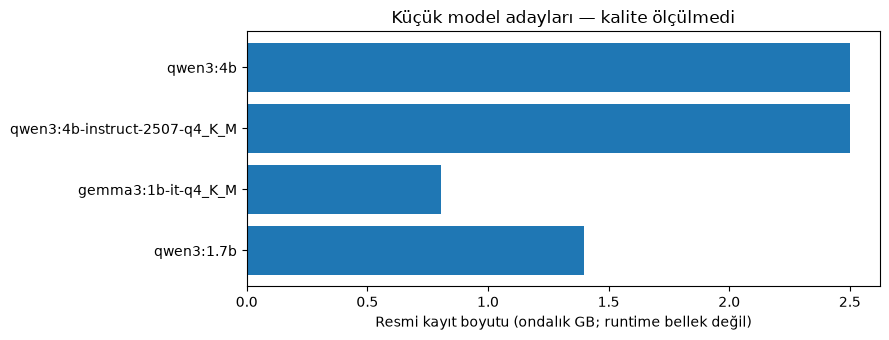

In [3]:
models=pd.read_csv(QA/'model_candidates.csv'); display(models[['tag','registry_size_GB','local_cache_manifest','position','limitation']])
fig,ax=plt.subplots(figsize=(9,3.5));ax.barh(models['tag'],models['registry_size_GB']);ax.set_xlabel('Resmi kayıt boyutu (ondalık GB; runtime bellek değil)');ax.set_title('Küçük model adayları — kalite ölçülmedi');fig.tight_layout();fig.savefig(FIG/'02_candidate_sizes.png',dpi=150);plt.show()

**Yorum:** 1.7b etiketli Qwen3 daha düşük ağırlık maliyetli birincil adaydır; kurulum/indirme kararı henüz verilmedi. Mevcut 4B-instruct önbelleği yeni indirme ihtiyacını kaldırabilir, fakat kullanılabilir bellek ve Türkçe kaynak sadakati yine doğrulanmalıdır. Boyuttan kalite üstünlüğü çıkarılamaz.

,Kayıt,Sayı
0,Belgeler,2
1,Fiziksel sayfalar,17
2,Birebir alıntılar,44


,key,file,physical_page,scope,purpose,qualifier
0,E_identity,pil.502.pdf,1,product_identity,identity,NaN
1,E_ingredients,pil.502.pdf,6,product_identity,identity,NaN
2,E_formulation,pil.502.pdf,6,product_identity,formulation,NaN
3,E_manufacturer,pil.502.pdf,6,product_identity,manufacturer,NaN
4,E_revision,pil.502.pdf,6,document_metadata,revision,NaN
5,E_excipient,pil.502.pdf,4,excipient_specific,warning,Named dyes;do not assign automatically to acti...
6,E_overdose,pil.502.pdf,4,overdose_context,warning,Overdose statement;not ordinary-use ADR list
7,E_adverse_p4,pil.502.pdf,4,product_specific,adverse_section,Section4 starts here and continues on physical5
8,E_adverse_p5,pil.502.pdf,5,product_specific,adverse_section,Continuation of section4;retain reporting/freq...
9,E_unknown_frequency,pil.502.pdf,5,product_specific,adverse_context,Frequency not known;no numeric probability


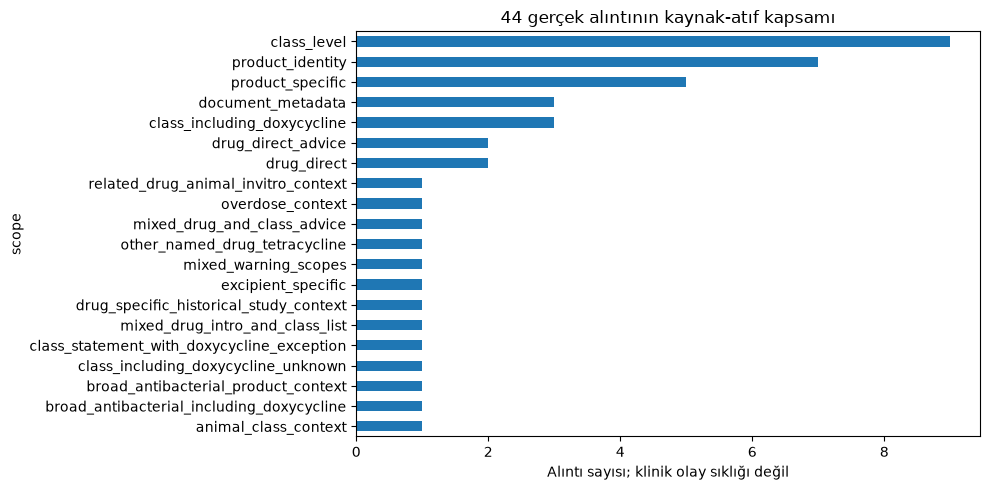

In [4]:
bundle,ann=contract.load_sources();q,p,a=contract.source_index(bundle,ann)
display(pd.DataFrame({'Kayıt':['Belgeler','Fiziksel sayfalar','Birebir alıntılar'],'Sayı':[len(bundle['documents']),len(p),len(q)]}))
scopes=pd.read_csv(QA/'quote_scope_inventory.csv');display(scopes[['key','file','physical_page','scope','purpose','qualifier']])
fig,ax=plt.subplots(figsize=(10,5));scopes.groupby('scope').size().sort_values().plot.barh(ax=ax);ax.set_xlabel('Alıntı sayısı; klinik olay sıklığı değil');ax.set_title('44 gerçek alıntının kaynak-atıf kapsamı');fig.tight_layout();fig.savefig(FIG/'03_source_scopes.png',dpi=150);plt.show()

**Yorum:** Kapsamlar kaynak incelemesi anotasyonlarıdır; klinik doğruluk için altın standart değildir. Uyarı, etkileşim veya hayvan kanıtını doğrudan ilaç yan etkisine çevirmemek, bu modülün tahmin modelinden ayrı kalmasını sağlar.

In [5]:
selected=['D_class_intro','D_class_renal','D_BUN_exception','E_unknown_frequency']
bykey={x['key']:x for x in ann}
display(pd.DataFrame([{'Anahtar':k,'Fiziksel sayfa':q[bykey[k]['quote_id']]['page_number'],'Kaynak alıntı (birebir)':q[bykey[k]['quote_id']]['quote']} for k in selected]))

,Anahtar,Fiziksel sayfa,Kaynak alıntı (birebir)
0,D_class_intro,7,The following adverse reactions have been obse...
1,D_class_renal,7,Renal Toxicity: Rise in BUN has been reported ...
2,D_BUN_exception,4,The antianabolic action of the tetracyclines m...
3,E_unknown_frequency,5,Other side effects of Erythromycin Tablets inc...


**Yorum:** Renal sınıf kaydına kaynak girişini ve doxycycline istisnasını birlikte taşıyoruz. Bu bağlam zorunluluğu yeni tasarım katmanında tutulur; eski 44 alıntı veya anotasyon değiştirilmez. Burada görülen İngilizce metinler gerçek kaynak alıntılarıdır; LLM çıktısı değildir.

In [6]:
scenarios=json.loads((QA/'frozen_scenarios.json').read_text(encoding='utf-8'))
display(pd.DataFrame(scenarios)[['scenario_id','source_keys','question_tr','acceptance_criteria_tr','source_characters','LLM_status']])
display(pd.read_csv(QA/'acceptance_criteria.csv'))

,scenario_id,source_keys,question_tr,acceptance_criteria_tr,source_characters,LLM_status
0,S01,"[E_identity, E_formulation]",Ürün ve formülasyon kaynakta nasıl tanımlanıyor?,Ürün beyanını ana ilaç kimliğine eşdeğerlik id...,537,NOT_RUN_NO_LLM
1,S02,[E_excipient],Yardımcı madde uyarısının kapsamını açıkla.,Yardımcı madde bağlamını erythromycin etkin ma...,109,NOT_RUN_NO_LLM
2,S03,[E_overdose],Aşırı doz bağlamındaki ifadeyi özetle.,Normal dozda sıklık/etki iddiası üretme.,108,NOT_RUN_NO_LLM
3,S04,"[E_adverse_p4, E_adverse_p5, E_unknown_frequency]",İki fiziksel sayfadaki yan etki anlatımını ve ...,Not known ifadesini sayısal risk veya yaygınlı...,3803,NOT_RUN_NO_LLM
4,S05,[D_direct_intro],Doğrudan doxycycline giriş ifadesini açıkla.,infrequent sözcüğünden sayısal sıklık türetme.,136,NOT_RUN_NO_LLM
5,S06,[D_class_GI],Gastrointestinal sınıf ifadesinin atfını açıkla.,Tetracycline sınıfı kaydını yalnız doxycycline...,679,NOT_RUN_NO_LLM
6,S07,[D_class_renal],Renal sınıf ifadesini doxycycline istisnasıyla...,Sınıf girişi ve D_BUN_exception iki cümlesi zo...,380,NOT_RUN_NO_LLM
7,S08,"[D_teeth, D_IH]",Sınıf içinde doxycycline dahil edilen uyarılar...,Sınıf-dahil kapsamını saf doğrudan ilaç kanıtı...,1573,NOT_RUN_NO_LLM
8,S09,[D_direct_candidiasis],Olasılık bildiren danışmanlık ifadesini açıkla.,might ifadesini kesinlik yapma; uyarıyı sıklık...,83,NOT_RUN_NO_LLM
9,S10,[D_tetracycline_methoxyflurane],Etkileşim cümlesindeki ilaç adını ve kapsamı b...,Adı tetracycline olan bileşiği sessizce doxycy...,108,NOT_RUN_NO_LLM


,criterion_id,criterion_tr,pass_rule
0,A01,"Her citation kanonik quote_id, belge SHA, fizi...",100%; otomatik
1,A02,Eksik/uydurulmuş/seçilmemiş kaynakta açıklama ...,100%; otomatik
2,A03,Sınıf/ilaç/uyarı/etkileşim/hayvan/istisna ve b...,Her iddia için insan incelemesi; tek ihlalde ret
3,A04,"Model skoru, SHAP, Δz, yeni yan etki veya MedD...",Ek alanlar ret; serbest metin ayrıca insan inc...
4,A05,predicted_by_GNN alanı yalnız trusted wrapper ...,LLM bu alanı yazamaz
5,A06,Kaynakta bulunmayan tamamlamalar ve klinik ris...,İnsan incelemesi; kaynak sadakati başarısızsa ret
6,A07,Context bağımlılıkları tam olmalı; sığmayan me...,Token kontrolü gelecekte zorunlu; bu tur NOT_M...
7,A08,Tekrarlar cherry-pick yapılmadan raporlanmalı,Gelecekte aynı vaka/seed3 tekrar; byte eşitliğ...
8,A09,Kritik senaryolarda kabul edilmeyen çıktı otom...,Tüm adaylar PENDING_HUMAN_REVIEW; otomatik açı...
9,A10,PDF/44 alıntı ve kabul edilen deneyler korunmalı,Önce/sonra SHA-256 doğrulaması


**Yorum:** Senaryolar, modelin başarısına göre seçilmedi; doğrudan/sınıf atfı, belirsizlik ve kaynak reddi gibi önceden belirli gereksinimleri kapsıyor. Kaynak karakter uzunluğu token sayısı değildir. Uzun vaka context bütçesine sığmıyorsa istisna kesilmez; vaka reddedilir veya bağlamı korunarak bölünür.

In [7]:
technical=json.loads((QA/'technical_validation.json').read_text(encoding='utf-8'))
display(pd.DataFrame([{'Kontrol':k,'Durum':v} for k,v in technical.items() if isinstance(v,(str,int,bool))]))
print((QA/'contract_tests_v1.txt').read_text(encoding='utf-8'))

test_01_all44_exact_spans (test_wp12_llm_contract.ContractTests.test_01_all44_exact_spans) ... ok
test_02_pending_not_semantic_pass (test_wp12_llm_contract.ContractTests.test_02_pending_not_semantic_pass) ... ok
test_03_missing_evidence (test_wp12_llm_contract.ContractTests.test_03_missing_evidence) ... ok
test_04_unknown_evidence (test_wp12_llm_contract.ContractTests.test_04_unknown_evidence) ... ok
test_05_unselected_real_evidence (test_wp12_llm_contract.ContractTests.test_05_unselected_real_evidence) ... ok
test_06_no_model_branch (test_wp12_llm_contract.ContractTests.test_06_no_model_branch) ... ok
test_07_no_model_or_label_fields (test_wp12_llm_contract.ContractTests.test_07_no_model_or_label_fields) ... ok
test_08_class_scope_not_direct (test_wp12_llm_contract.ContractTests.test_08_class_scope_not_direct) ... ok
test_09_class_context_required (test_wp12_llm_contract.ContractTests.test_09_class_context_required) ... ok
test_10_renal_exception_required (test_wp12_llm_contract.Contr

,Kontrol,Durum
0,status,DESIGN_TECHNICAL_PASS_LLM_NOT_RUN
1,tests_passed,24
2,source_documents,2
3,source_pages,17
4,source_quotes,44
5,scenarios_defined,19
6,scenario_source_references_valid,True
7,LLM_scenario_results,NOT_RUN_NO_LLM
8,semantic_fidelity,NOT_MEASURED
9,runtime_compatibility,NOT_TESTED


**Yorum:** Geçen teknik testler modelin Türkçe özet başarısı değildir. Serbest metnin anlam sadakati henüz ölçülmedi. Yapısal olarak geçerli her aday insan anlam incelemesinde bekler; gerçek LLM, kurulum veya model indirme için kullanıcı onayı gerekir. **WP13 başlatılmadı.**